# 04 — PSF, apertures, jitter and defocus

At 600 nm the diffraction-limited PSF of a 3.065 m telescope has a FWHM of about 41 mas, i.e.
**2.4 pixels**: the WCC is close to critically sampled, and a tenth of the light of a star lands in
one pixel. That is why bright stars saturate (notebook 02), and why the aperture, the pointing
jitter and a deliberate defocus all change the answer.

In this notebook:
1. a simulated image stamp: `ImageSimulator`, radial profile, encircled energy,
2. the photometric aperture and `optimize=True`,
3. pointing jitter,
4. the defocused modes `zwo:r+1` and `zwo:bb2`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import wcc_etc
from wcc_etc import Simulation, get_scene

wcc_etc.set_wcc_style()

from wcc_etc import ImageSimulator

READS = (1, 2, 3, 6, 10, 30, 60, 120, 240)

def choose_reads(sim, t, reads=READS, **kw):
    """Smallest read count whose per-frame image has no saturated pixel; (None, last result) if none works."""
    for n in reads:
        r = sim.get_image_snr(t, n_reads=n, warn=False, **kw)
        if not np.any(r["saturated"]):
            return n, r
    return None, r

***
## 1. A simulated image

`ImageSimulator` renders a stamp (electrons, with photon, background, dark and read noise) for one
exposure. The returned object has `image_e`, `image_clean`, `saturation_mask` and plot methods.

[wcc_etc] note: even n_pixels is rounded up by 1 to center the PSF peak (shown once).


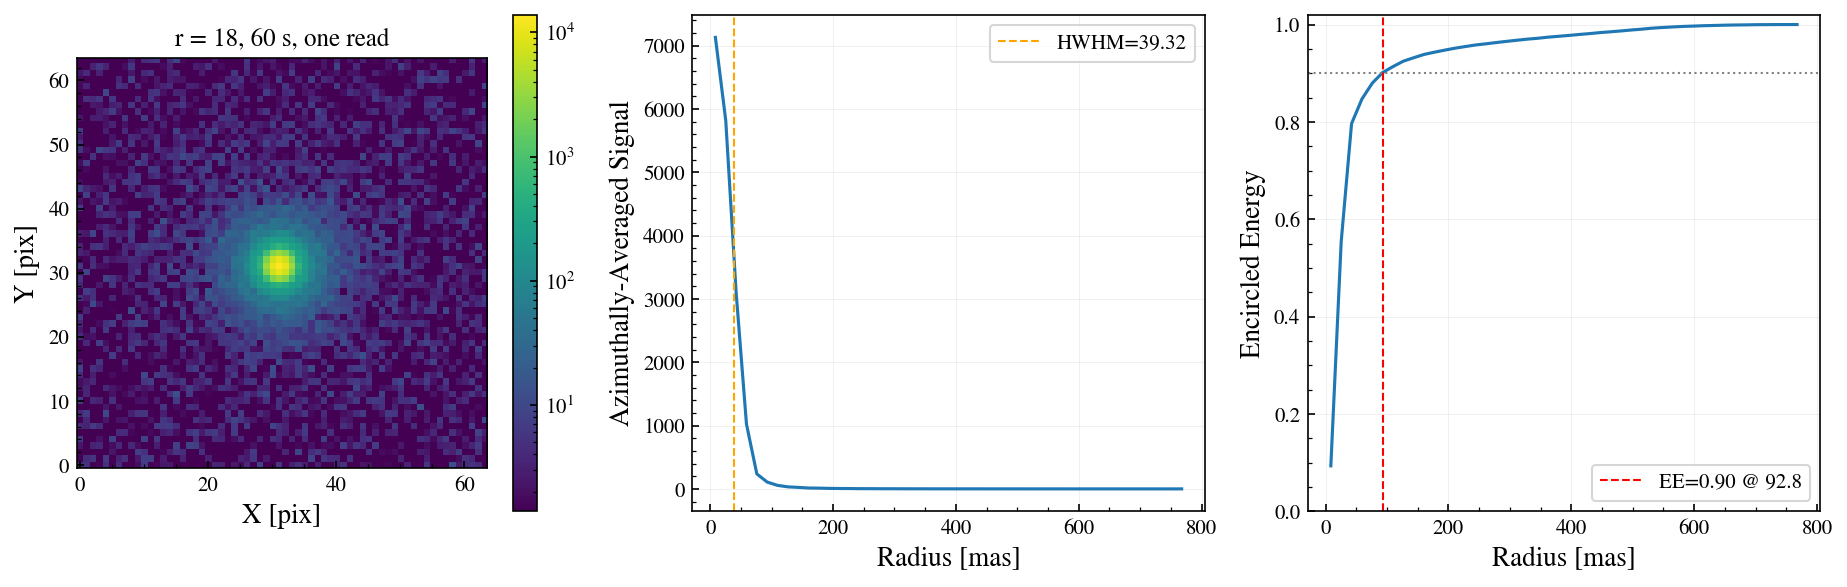

16.87 mas/px; peak pixel 13967 e-, 9.4% of the light


In [2]:
scene = get_scene("G2V", mag=18, bandpass="sdss_r", magsys="abmag")
img = ImageSimulator.from_sensorfilter("zwo:r", scene, npix=64).simulate(60, seed=1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
img.plot_image(ax=axes[0], title="r = 18, 60 s, one read")
img.plot_radial(ax=axes[1])
img.plot_encircled_energy(ax=axes[2])
plt.show()
print(f"{img.pixel_scale_mas:.2f} mas/px; peak pixel {img.image_clean.max():.0f} e-, {img.image_clean.max() / img.image_clean.sum():.1%} of the light")

***
## 2. The aperture

`get_image_snr` measures the source in a circular aperture of radius `r_aper_mas` (default: set
by the PSF, about 70 mas). A small aperture loses signal; a large one adds background and read noise.
`optimize=True` searches the radius that maximizes the SNR.

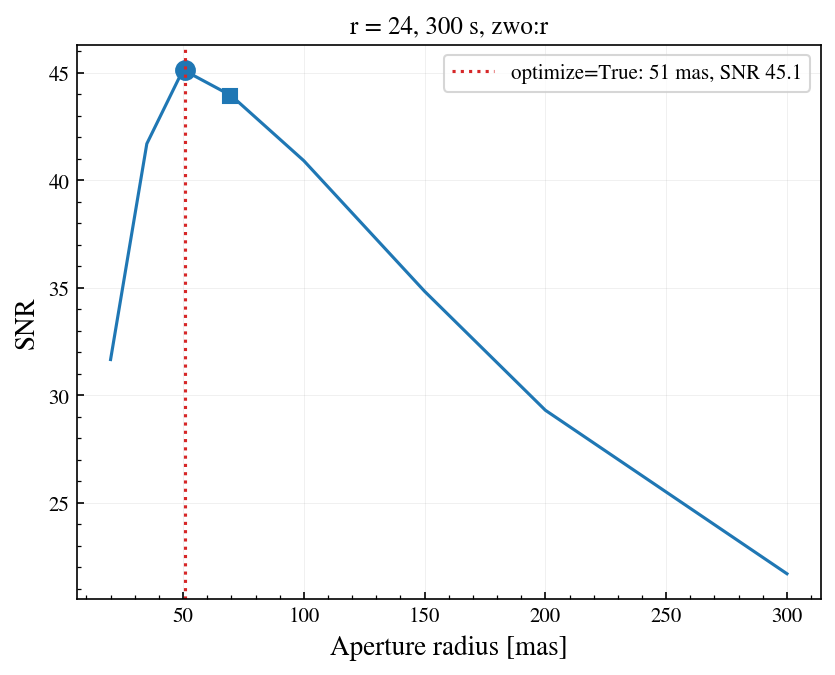

In [3]:
sim = Simulation.from_sensorfilter("zwo:r", scene)
sim.update(source__mag=24.0)
radii = np.array([20, 35, 50, 70, 100, 150, 200, 300])
fig, ax = sim.plot_snr_vs_aperture(radii, time=300)
best = sim.get_image_snr(300, optimize=True, warn=False)
ax.axvline(best["r_aper_mas"], color="C3", ls=":", label=f"optimize=True: {best['r_aper_mas']:.0f} mas, SNR {best['snr']:.1f}")
ax.set(title="r = 24, 300 s, zwo:r")
ax.legend()
plt.show()

***
## 3. Pointing jitter

The telescope jitters by 10 mas (1 sigma) by default. `jitter_sigma_mas` convolves the PSF with a
Gaussian of that width: more jitter spreads the light (lower peak pixel, bright stars saturate
later) and lowers the SNR of faint sources.

In [4]:
print(f"{'jitter [mas]':>12} {'peak fraction':>13} {'SNR r=24, 300 s':>15}")
for j in (0, 10, 30, 100, 300):
    print(f"{j:12d} {sim.peak_pixel_fraction(jitter_sigma_mas=j):13.3f} {sim.get_image_snr(300, jitter_sigma_mas=j, warn=False)['snr']:15.1f}")

jitter [mas] peak fraction SNR r=24, 300 s
           0         0.123            44.0
          10         0.096            43.9
          30         0.033            40.8


         100         0.004            15.9


         300         0.000             2.7


***
## 4. Defocus

The labels `zwo:r+1` / `zwo:r-1` (one wave of defocus) and `zwo:bb2` (two waves) use measured
defocused PSFs instead of the Airy pattern. The light is spread over ~50 times more pixels, so a
star ~4 magnitudes brighter fits in the well, at the price of SNR for faint sources and a much
larger aperture.

> ✏️ **Before you run the next cell:** an r = 12 G2V star needs 120 reads per minute in focus (notebook 02). With one wave of defocus, how many? Write your guess down (or put it in the room poll), then run.

label    peak fraction  n_pix reads / 60 s     SNR
zwo:r           0.0956     57          240    5658
zwo:r+1         0.0018   5465            6    5993


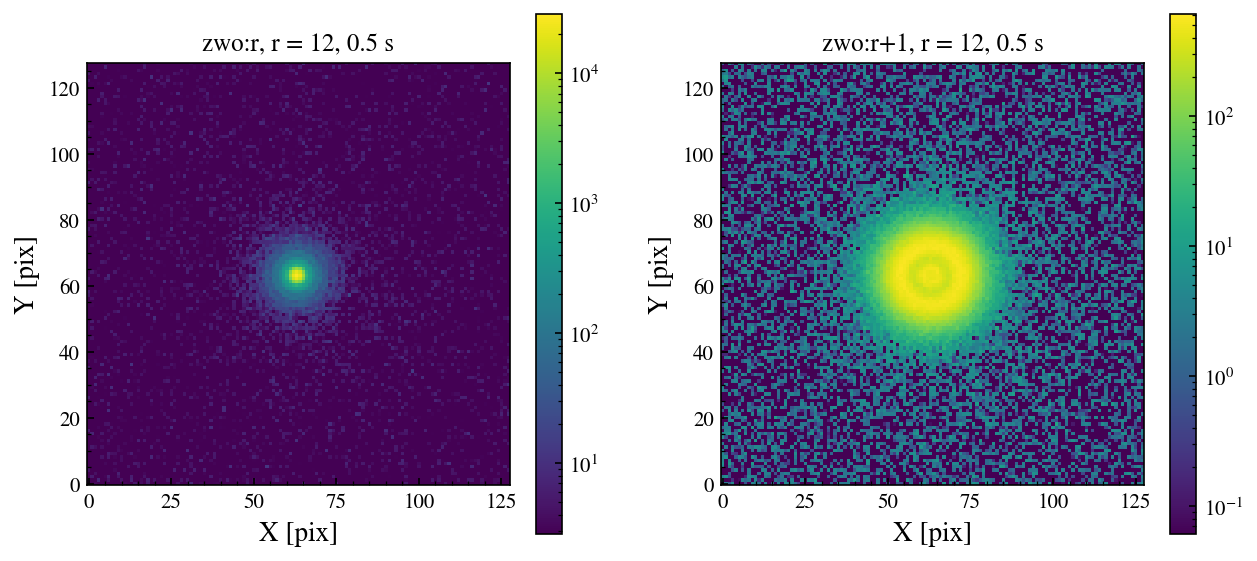

In [5]:
bright = get_scene("G2V", mag=12, bandpass="sdss_r", magsys="abmag")
print(f"{'label':8s} {'peak fraction':>13} {'n_pix':>6} {'reads / 60 s':>12} {'SNR':>7}")
for label in ("zwo:r", "zwo:r+1"):
    s = Simulation.from_sensorfilter(label, bright)
    n, r = choose_reads(s, 60)
    print(f"{label:8s} {s.peak_pixel_fraction():13.4f} {r['n_pix']:6d} {str(n) if n else 'none':>12} {r['snr']:7.0f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, label in zip(axes, ("zwo:r", "zwo:r+1")):
    ImageSimulator.from_sensorfilter(label, bright, npix=128).simulate(0.5, seed=1).plot_image(ax=ax, title=f"{label}, r = 12, 0.5 s")
plt.show()

The faint end pays for it:

In [6]:
faint = get_scene("G2V", mag=24, bandpass="sdss_r", magsys="abmag")
for label in ("zwo:r", "zwo:r+1"):
    s = Simulation.from_sensorfilter(label, faint)
    print(f"{label:8s}: r = 24, 300 s, SNR = {s.get_image_snr(300, warn=False)['snr']:5.1f} (aperture {s.get_image_snr(300, warn=False)['r_aper_mas']:.0f} mas)")

zwo:r   : r = 24, 300 s, SNR =  43.9 (aperture 70 mas)
zwo:r+1 : r = 24, 300 s, SNR =  21.9 (aperture 241 mas)


> 🤖 **Ask Jupyter AI:** *For a G2V star of r = 12 observed for 60 s, compare zwo:r with the smallest unsaturated read split against zwo:r+1 with one read: which gives the better photometric precision in ppm, and why? Write the comparison as a small table.*
>
> Then change the star to r = 9 and r = 15 and see where the answer flips.

***
## Summary

```python
ImageSimulator.from_sensorfilter("zwo:r", scene, npix=64).simulate(60, seed=1)   # .plot_image(), .plot_radial(), .plot_encircled_energy()
sim.get_image_snr(t, r_aper_mas=100)      # fixed aperture
sim.get_image_snr(t, optimize=True)       # best aperture
sim.get_image_snr(t, jitter_sigma_mas=30) # pointing jitter
Simulation.from_sensorfilter("zwo:r+1", scene)   # one wave of defocus; "zwo:bb2" two waves
```

Next: [05 — light curves](05_light_curves.ipynb).